|<h2>Book:</h2>|<h1><a href="https://open.substack.com/pub/mikexcohen/p/llm-breakdown-16-tokenization-words" target="_blank">50 ML projects to understand LLMs</a></h1>|
|-|:-:|
|<h2>Project:</h2>|<h1><b>[20] Perplexity over time and text</b></h1>|
|<h2>Author:<h2>|<h1>Mike X Cohen, <a href="https://sincxpress.com" target="_blank">sincxpress.com</a></h1>|

<br>

<i>Using the code without reading the book may lead to confusion or errors.</i>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

import requests
from datasets import load_dataset

from tqdm import tqdm

import torch
import torch.nn.functional as F

from transformers import AutoModelForCausalLM, AutoTokenizer

In [ ]:
### matplotlib adjustments (commented lines are for dark mode)

# svg plots (higher-res)
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

plt.rcParams.update({
    # 'figure.facecolor': '#282a2c',
    # 'figure.edgecolor': '#282a2c',
    # 'axes.facecolor':   '#282a2c',
    # 'axes.edgecolor':   '#DDE2F4',
    # 'axes.labelcolor':  '#DDE2F4',
    # 'xtick.color':      '#DDE2F4',
    # 'ytick.color':      '#DDE2F4',
    # 'text.color':       '#DDE2F4',
    'axes.spines.right': False,
    'axes.spines.top':   False,
    'axes.titleweight': 'bold',
    'axes.labelweight': 'bold',
    'savefig.dpi':50,
})

# **What does perplexity mean?**

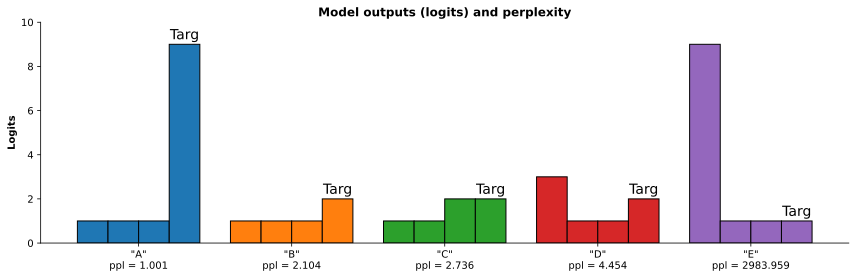

In [ ]:
# each list item is model outputs (logits)
situations = [
    [ 1,1,1,9 ],
    [ 1,1,1,2 ],
    [ 1,1,2,2 ],
    [ 3,1,1,2 ],
    [ 9,1,1,1 ] ]

y = len(situations[0])-1 # final logit is the target category index

# create a figure
plt.figure(figsize=(12,4))
xlabls = [] # x-axis tick labels
label_code = ['A','B','C','D','E'] # for lettering the x-axis labels

for i,sit in enumerate(situations):

  # raw model output (logits)
  model_output = torch.tensor([sit],dtype=torch.float32)

  # log-softmax
  log_softmax = F.log_softmax(model_output,dim=-1)

  # negative log-likelihood loss
  loss = -log_softmax[0,y]

  # perplexity
  ppl = torch.exp(loss)

  # draw the results
  plt.bar(np.array([.7,.9,1.1,1.3])+i,model_output[0].detach(),width=.2,edgecolor='k')
  plt.text(1.3+i,model_output[0,-1].detach()+.1,'Targ',font={'size':14},ha='center',va='bottom')

  # x-axis tick label
  xlabls.append(f'"{label_code[i]}"\nppl = {ppl.item():.3f}')



plt.gca().set(title='Model outputs (logits) and perplexity',ylabel='Logits',
              xticks=range(1,len(situations)+1),xticklabels=xlabls,ylim=[0,10])

plt.tight_layout()
plt.savefig('ch4_proj20_part0.png')
plt.show()

# **Part 1: Perplexity over time**

In [ ]:
# load pretrained GPT-2 model and tokenizer
tokenizer = AutoTokenizer.from_pretrained('gpt2')
gpt2 = AutoModelForCausalLM.from_pretrained('gpt2')
gpt2.eval()

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [ ]:
# connect to GPU if available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
gpt2.to(device);

In [ ]:
# import Frankenstein
url = 'https://www.gutenberg.org/cache/epub/84/pg84.txt'
text = requests.get(url).text
print(text[:1000])

The Project Gutenberg eBook of Frankenstein; or, the modern prometheus
    
This eBook is for the use of anyone anywhere in the United States and
most other parts of the world at no cost and with almost no restrictions
whatsoever. You may copy it, give it away or re-use it under the terms
of the Project Gutenberg License included with this eBook or online
at www.gutenberg.org. If you are not located in the United States,
you will have to check the laws of the country where you are located
before using this eBook.

Title: Frankenstein; or, the modern prometheus

Author: Mary Wollstonecraft Shelley


        
Release date: October 1, 1993 [eBook #84]
                Most recently updated: February 10, 2026

Language: English

Other information and formats: www.gutenberg.org/ebooks/84

Credits: Judith Boss, Christy Phillips, Lynn Hanninen and David Meltzer. HTML version by Al Haines.
        Further corrections by Menno de Leeuw.


*** START OF THE PROJECT GUTEN


In [ ]:
# tokenize the book
tokens = tokenizer.encode(text,return_tensors='pt')
num_tokens = tokens.shape[-1]
print(f'Number of tokens: {num_tokens:,}')

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (114213 > 1024). Running this sequence through the model will result in indexing errors


Number of tokens: 114,213


In [ ]:
# max sequence length
seq_len = gpt2.config.n_positions
print(f'Sequence length: {seq_len}')

# how many samples fit into the data
nSegments = num_tokens//seq_len
print(f'Number of non-overlapping segments: {nSegments:,}')

Sequence length: 1024
Number of non-overlapping segments: 111


In [ ]:
perplexities = np.zeros(nSegments)

sum_losses = 0.

for segi in tqdm(range(nSegments)):

  # 1) start and end indices
  start = segi * seq_len
  end = start + seq_len

  # 2) extract the data and push to the GPU
  X = tokens[0][start:end].unsqueeze(0).to(device)

  # 3) forward pass
  with torch.no_grad():
    outputs = gpt2(X,labels=X)

  # 4) accumulated loss for later perplexity calculations
  sum_losses += outputs.loss.item()

  # 5) per-segment perplexity
  perplexities[segi] = torch.exp(outputs.loss).item()

# 6) calculate perplexity
ave_perplexity = torch.exp( torch.tensor(sum_losses) / nSegments )

100%|██████████| 111/111 [00:10<00:00, 10.79it/s]


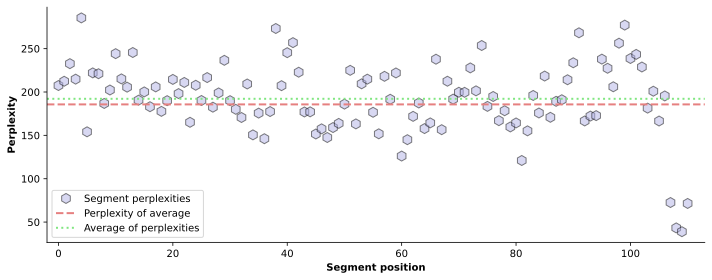

In [ ]:
plt.figure(figsize=(10,4))

plt.plot(perplexities,'kh',markersize=10,markerfacecolor=[.7,.7,.9,.5],label='Segment perplexities')
plt.axhline(ave_perplexity,linestyle='--',color=[.9,.5,.5],linewidth=2,label='Perplexity of average')
plt.axhline(perplexities.mean(),linestyle=':',color=[.5,.9,.5],linewidth=2,label='Average of perplexities')

plt.legend()
plt.gca().set(xlabel='Segment position',ylabel='Perplexity',xlim=[-2,nSegments+2])

plt.tight_layout()
plt.savefig('ch4_proj20_part1.png')
plt.show()

# **Part 2: A perplexity function**

In [ ]:
def calc_perplex(tokens,model=gpt2,seq_len=gpt2.config.n_positions):

  # number of segments in the total token sequence
  nSegments = torch.numel(tokens)//seq_len

  # initialize losses
  sum_losses = 0.

  for i in range(nSegments):

    # find start and end indices
    start = i*seq_len
    end = start + seq_len

    # get the token sequence (with batch dimension)
    X = tokens[0,start:end].unsqueeze(0).to(device)

    # forward pass
    with torch.no_grad():
      outputs = model(X,labels=X)

    # calculate and store this batch's loss
    sum_losses += outputs.loss.item()

  # after segments loop, perplexity = exp(average per-token losses over this segment)
  perplexity = torch.exp( torch.tensor(sum_losses) / nSegments )

  return perplexity

In [ ]:
calc_perplex(tokens)

tensor(185.7326)

In [ ]:
ave_perplexity

tensor(185.7326)

# **Part 3: Impact of sequence length**

In [ ]:
seq_lengths = 2**np.arange(5,11)

perp_by_len = np.zeros(len(seq_lengths))

for i in tqdm(range(len(seq_lengths))):
  perp_by_len[i] = calc_perplex(tokens,seq_len=seq_lengths[i])

print('\n')
for i in range(len(seq_lengths)):
  print(f'Sequence length {seq_lengths[i]:4} has perplexity {perp_by_len[i]:6.2f}')

100%|██████████| 6/6 [02:13<00:00, 22.27s/it]



Sequence length   32 has perplexity 804.71
Sequence length   64 has perplexity 454.13
Sequence length  128 has perplexity 308.42
Sequence length  256 has perplexity 241.31
Sequence length  512 has perplexity 205.10
Sequence length 1024 has perplexity 185.73


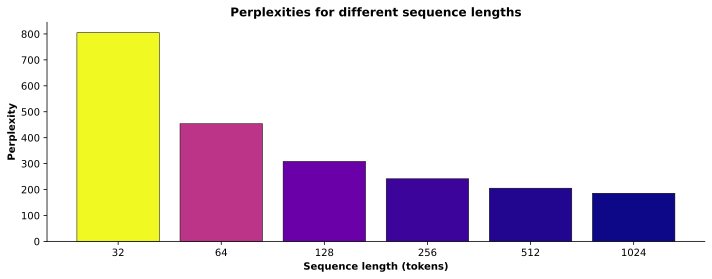

In [ ]:
plt.figure(figsize=(10,4))

perpl_scaled = (perp_by_len - perp_by_len.min()) / (perp_by_len.max() - perp_by_len.min())

plt.bar(range(len(seq_lengths)),perp_by_len,edgecolor='k',linewidth=.5,
        color=plt.cm.plasma(perpl_scaled))
plt.gca().set(xticks=range(len(perp_by_len)),xticklabels=seq_lengths,xlabel='Sequence length (tokens)',
              ylabel='Perplexity',title='Perplexities for different sequence lengths')

plt.tight_layout()
plt.savefig('ch4_proj20_part3.png')
plt.show()

# **Part 4: Perplexities in different texts**

In [ ]:
# all books have the same url format; they are unique by numerical code
baseurl='https://www.gutenberg.org/cache/epub/'

bookurls = [
    # code       title
    ['84',    'Frankenstein'    ],
    ['64317', 'GreatGatsby'     ],
    ['11',    'AliceWonderland' ],
    ['1513',  'RomeoJuliet'     ],
    ['76',    'HuckFinn'        ],
    ['219',   'HeartDarkness'   ],
    ['2591',  'GrimmsTales'     ],
    ['2148',  'EdgarAllenPoe'   ],
    ['36',    'WarOfTheWorlds'  ],
    ['829',   'GulliversTavels'],

]

In [ ]:
ppls = np.zeros(len(bookurls))

for i,(code,title) in enumerate(bookurls):

  # get the text tokens
  fullurl = baseurl + code + '/pg' + code + '.txt'
  text = requests.get(fullurl).text
  tokens = tokenizer.encode(text,return_tensors='pt')

  # just the first 50k tokens for speed and direct comparison
  tokens = tokens[0][:50000].unsqueeze(0)

  # calculate perplexity
  ppls[i] = calc_perplex(tokens)

  print(f'{title:>16} has perplexity {ppls[i]:6.2f}')

    Frankenstein has perplexity 198.26
     GreatGatsby has perplexity 150.25
 AliceWonderland has perplexity  95.68
     RomeoJuliet has perplexity 268.51
        HuckFinn has perplexity 148.09
   HeartDarkness has perplexity 176.19
     GrimmsTales has perplexity  94.15
   EdgarAllenPoe has perplexity  66.42
  WarOfTheWorlds has perplexity 213.91
GulliversTravels has perplexity 162.49


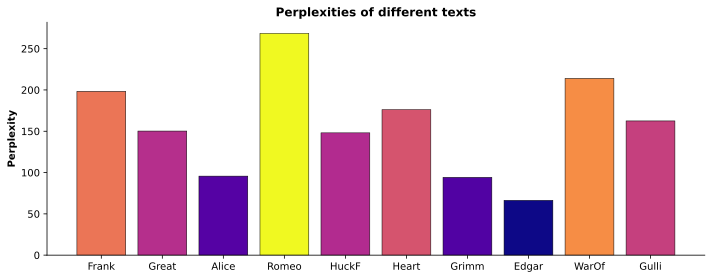

In [ ]:
plt.figure(figsize=(10,4))

# min-max scaling for coloring the bars
ppls_scaled = (ppls - ppls.min()) / (ppls.max() - ppls.min())

# and draw the bars
plt.bar(range(len(ppls)),ppls,edgecolor='k',linewidth=.5,
        color=plt.cm.plasma(ppls_scaled))
plt.gca().set(xticks=range(len(ppls)),xticklabels=[bookurls[i][1][:5] for i in range(len(bookurls))],
              ylabel='Perplexity',title='Perplexities of different texts')

plt.tight_layout()
plt.savefig('ch4_proj20_part4.png')
plt.show()

# **Part 5: Perplexities in different models**

In [ ]:
# dictionary of modelname:identifier
model_ids = {
    'small':  'gpt2',        # 124M
    'medium': 'gpt2-medium', # 355M
    'large':  'gpt2-large',  # 774M
    'xl':     'gpt2-xl'      # 1.6B
}

# load all models into a dictionary
models = {}
for name, id in model_ids.items():
  models[name] = AutoModelForCausalLM.from_pretrained(id).to(device)
  models[name].eval()

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/718 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.52GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/292 [00:00<?, ?it/s]

...

config.json:   0%|          | 0.00/689 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 6.43GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/580 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

In [ ]:
perp_models = np.zeros(len(models))

for i,(name, model) in enumerate(models.items()):
  perp_models[i] = calc_perplex(tokens,model=model) # tokens from final book in previous for-loop
  print(f'Perplexity of {perp_models[i]:6.2f} for GPT2-{name}')

Perplexity of 162.49 for GPT2-small
Perplexity of  77.92 for GPT2-medium
Perplexity of 294.19 for GPT2-large
Perplexity of 279.73 for GPT2-xl


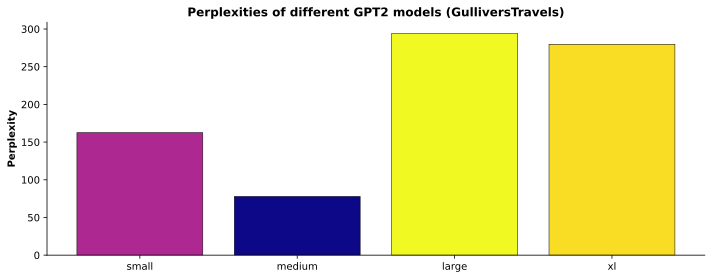

In [ ]:
plt.figure(figsize=(10,4))

perp_models_scaled = (perp_models - perp_models.min()) / \
                     (perp_models.max() - perp_models.min())

plt.bar(range(len(perp_models)),perp_models,edgecolor='k',linewidth=.5,
        color=plt.cm.plasma(perp_models_scaled))
plt.gca().set(xticks=range(len(perp_models)),xticklabels=list(models.keys()),
              ylabel='Perplexity',title=f'Perplexities of different GPT2 models ({title})')

plt.tight_layout()
plt.savefig('ch4_proj20_part5.png')
plt.show()

# **Part 6: Perplexities in different models (Wikitext)**

In [ ]:
# note: over-writing 'tokens' from earlier
text = load_dataset('Salesforce/wikitext','wikitext-2-raw-v1',split='test')

# join the text samples
tokens = tokenizer.encode('\n'.join(text['text'][:2000]),return_tensors='pt').to(device)
torch.numel(tokens)

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

...

wikitext-2-raw-v1/validation-00000-of-00(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

136702

In [ ]:
perp_models = np.zeros(len(models))

for i,(name, model) in enumerate(models.items()):
  perp_models[i] = calc_perplex(tokens,model=model)
  print(f'Perplexity of {perp_models[i]:.2f} for GPT2-{name}')

Perplexity of 29.77 for GPT2-small
Perplexity of 21.40 for GPT2-medium
Perplexity of 18.70 for GPT2-large
Perplexity of 16.91 for GPT2-xl


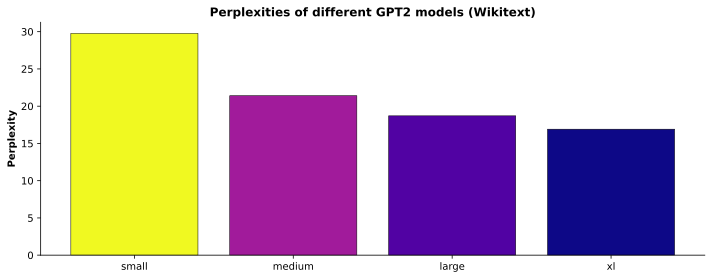

In [ ]:
plt.figure(figsize=(10,4))

perp_models_scaled = (perp_models - perp_models.min()) / \
                     (perp_models.max() - perp_models.min())

plt.bar(range(len(perp_models)),perp_models,edgecolor='k',linewidth=.5,
        color=plt.cm.plasma(perp_models_scaled))
plt.gca().set(xticks=range(len(perp_models)),xticklabels=list(models.keys()),
              ylabel='Perplexity',title='Perplexities of different GPT2 models (Wikitext)')

plt.tight_layout()
plt.savefig('ch4_proj20_part6.png')
plt.show()